# 🥾➿ Experiment 03. Bootstrap Distribution 🥾➿

This experiment examines what distribution of estimates produces a bootstrap confidence interval.

Using 10,000 paired bootstrap replicates based on the original sample (n = 300), I explore the distributions of Cohen's κ and Δκ and examine how their percentiles are used to construct 95% confidence intervals.

## Contents

1. **Question**
2. **Data and Procedure**
3. **What I Will Examine**
4. **Reproduction Check**
5. **Bootstrap Distribution**
   - 5.1. Baseline κ
   - 5.2. Δκ by Condition
   - 5.3. Percentile Intervals
6. **Observations**

This notebook reads a local file (the human labels) from the original study's repository, so it runs only on the local machine.


## 1. Question 🤔

What distribution of estimates produces a bootstrap confidence interval?

In the original study, exclusion-rule replacement produced the following result.

| Measure | Value |
|---|---:|
| Estimated Δκ | −0.1062 |
| 95% Bootstrap CI | [−0.1576, −0.0556] |

The confidence interval provides two endpoints, but these values alone do not reveal the center or shape of the bootstrap distribution.

This experiment examines the distribution of bootstrap estimates and how its 2.5th and 97.5th percentiles produce the reported confidence interval.

## 2. Data and Procedure

This experiment examines 10,000 bootstrap replicates from the original study.

Each replicate sampled 300 utterances with replacement. The human label and all six condition labels were kept together, and the same draw was used across conditions.

The replicates were regenerated using the original scoring functions, seed 20260919, and NumPy 2.3.5.

The results are stored in `preview/replicates.csv`.

| Column | Content |
|---|---|
| `replicate` | Replicate number (1–10,000) |
| `kappa_baseline` | Baseline κ for each replicate |
| `delta_kappa_<condition>` | Δκ for each of the four replacement conditions |

This notebook reads the saved replicates without resampling. Original point estimates are taken from the scoring record.

**Reproduction:** `preview/make_replicates.py`

**Source:** [decisions/06-analysis.md §6.2.1](https://github.com/geekinthegit/coding-manual-ablation/blob/main/decisions/06-analysis.md)

In [5]:
# 2. Data and Procedure — load the saved replicates and the point estimates from the record

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPLICATES = Path("preview") / "replicates.csv"
if not REPLICATES.exists():
    raise FileNotFoundError(f"Required input not found: {REPLICATES} (run this notebook from experiments/03-bootstrap-distribution)")

REPLACEMENTS = [
    "definition_replacement",
    "example_replacement",
    "exclusion_rule_replacement",
    "negative_control",
]
N, B = 300, 10_000

# Bootstrap replicates (preview/make_replicates.py)
replicates = pd.read_csv(REPLICATES)
EXPECTED_COLUMNS = ["replicate", "kappa_baseline", *[f"delta_kappa_{c}" for c in REPLACEMENTS]]
assert len(replicates) == B
assert list(replicates.columns) == EXPECTED_COLUMNS
assert replicates["replicate"].tolist() == list(range(1, B + 1))
assert replicates.notna().all().all()

# Point estimates from the scoring record (Sections 8 and 9), computed on the original 300 utterances
point = {
    "kappa_baseline": 0.6085,
    "delta_kappa_definition_replacement": -0.0018,
    "delta_kappa_example_replacement": -0.0611,
    "delta_kappa_exclusion_rule_replacement": -0.1062,
    "delta_kappa_negative_control": -0.0232,
}

# 95% intervals from the scoring record (Section 9)
record_ci = {
    "kappa_baseline": (0.5266, 0.6846),
    "delta_kappa_definition_replacement": (-0.0384, 0.0360),
    "delta_kappa_example_replacement": (-0.1047, -0.0191),
    "delta_kappa_exclusion_rule_replacement": (-0.1576, -0.0556),
    "delta_kappa_negative_control": (-0.0581, 0.0118),
}

print(f"Replicates loaded: {len(replicates)} rows, {len(EXPECTED_COLUMNS) - 1} statistics")

Replicates loaded: 10000 rows, 5 statistics


## 3. What I Will Examine

- **Center** How close is the median of the replicates to the point estimate, for baseline κ and for each Δκ?

- **Spread** How wide is each 95% interval, and what is the standard deviation of the replicates?

- **Shape** Is each distribution symmetric around its center, and does it have a longer tail on one side?

- **Interval position** Which Δκ intervals include 0, and which lie entirely on one side of it?

- **Δκ versus baseline κ** Is the Δκ interval narrower than the baseline κ interval, and what in the resampling procedure would make it so? The correlation between baseline κ and condition κ across replicates is computed in Section 5.2 for this question.

## 4. Reproduction Check

The 2.5th and 97.5th percentiles of each replicate column are computed and compared with the reported 95% confidence intervals.
The replicates were regenerated using the original code, input data, row order, seed, and NumPy version.
Matching percentiles verify reproduction of the reported interval bounds, but do not by themselves establish that all 10,000 replicate values are identical.
Two kinds of values appear in the comparison table. The point estimate is a statistic of the original sample of 300 utterances and is taken from the record. The percentiles, median, mean, and standard deviation are statistics of the 10,000 resampled estimates. The median or mean of the replicates is not required to equal the point estimate.

**Source:** [Main Scoring Record, Section 9](https://github.com/geekinthegit/coding-manual-ablation/blob/main/reports/main-scoring-record-2026-09-24.md)

In [10]:
# 4. Reproduction Check — percentiles of the replicates against the record intervals

rows = []
for col in ["kappa_baseline", *[f"delta_kappa_{c}" for c in REPLACEMENTS]]:
    values = replicates[col].to_numpy()
    lo, hi = np.percentile(values, [2.5, 97.5], method="linear")
    rec_lo, rec_hi = record_ci[col]
    assert round(lo, 4) == rec_lo, (col, lo, rec_lo)
    assert round(hi, 4) == rec_hi, (col, hi, rec_hi)
    rows.append({
        "statistic": col,
        "point estimate": point[col],
        "p2.5": lo,
        "p50": np.median(values),
        "p97.5": hi,
        "mean": values.mean(),
        "SD": values.std(ddof=1),
        "record CI": f"[{rec_lo:.4f}, {rec_hi:.4f}]",
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                             statistic  point estimate    p2.5     p50   p97.5    mean     SD          record CI
                        kappa_baseline          0.6085  0.5266  0.6083  0.6846  0.6075 0.0401   [0.5266, 0.6846]
    delta_kappa_definition_replacement         -0.0018 -0.0384 -0.0019  0.0360 -0.0017 0.0190  [-0.0384, 0.0360]
       delta_kappa_example_replacement         -0.0611 -0.1047 -0.0608 -0.0191 -0.0610 0.0217 [-0.1047, -0.0191]
delta_kappa_exclusion_rule_replacement         -0.1062 -0.1576 -0.1062 -0.0556 -0.1063 0.0260 [-0.1576, -0.0556]
          delta_kappa_negative_control         -0.0232 -0.0581 -0.0233  0.0118 -0.0234 0.0178  [-0.0581, 0.0118]


## 5. Bootstrap Distribution

Each histogram shows the 10,000 replicate values of one statistic. The vertical lines mark the point estimate (from the scoring record) and the 2.5th and 97.5th percentiles that form the reported interval. The Δκ figures also mark 0.

### 5.1. Baseline κ

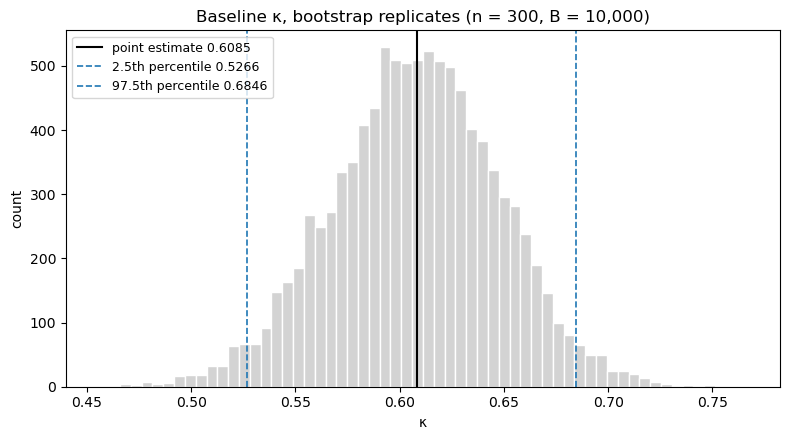

median 0.6083, mean 0.6075, SD 0.0401


In [11]:
# 5.1. Baseline κ — histogram of the 10,000 replicates

col = "kappa_baseline"
values = replicates[col].to_numpy()
lo, hi = np.percentile(values, [2.5, 97.5], method="linear")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(values, bins=60, color="lightgray", edgecolor="white")
ax.axvline(point[col], color="black", linewidth=1.5, label=f"point estimate {point[col]:.4f}")
ax.axvline(lo, color="tab:blue", linestyle="--", linewidth=1.2, label=f"2.5th percentile {lo:.4f}")
ax.axvline(hi, color="tab:blue", linestyle="--", linewidth=1.2, label=f"97.5th percentile {hi:.4f}")
ax.set_title("Baseline κ, bootstrap replicates (n = 300, B = 10,000)")
ax.set_xlabel("κ")
ax.set_ylabel("count")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"median {np.median(values):.4f}, mean {values.mean():.4f}, SD {values.std(ddof=1):.4f}")

### 5.2. Δκ by Condition

The bootstrap distributions of Δκ are shown separately for the four replacement conditions and together in a combined figure.

For each replicate, condition κ is reconstructed by adding Δκ to baseline κ.

The correlation between baseline κ and condition κ is calculated. The widths of their 95% confidence intervals are then compared with the interval width of Δκ. 

The last column, √(2(1 − r)), is the width ratio expected when baseline κ and condition κ have the same spread and correlation r. It is compared with the observed ratio.

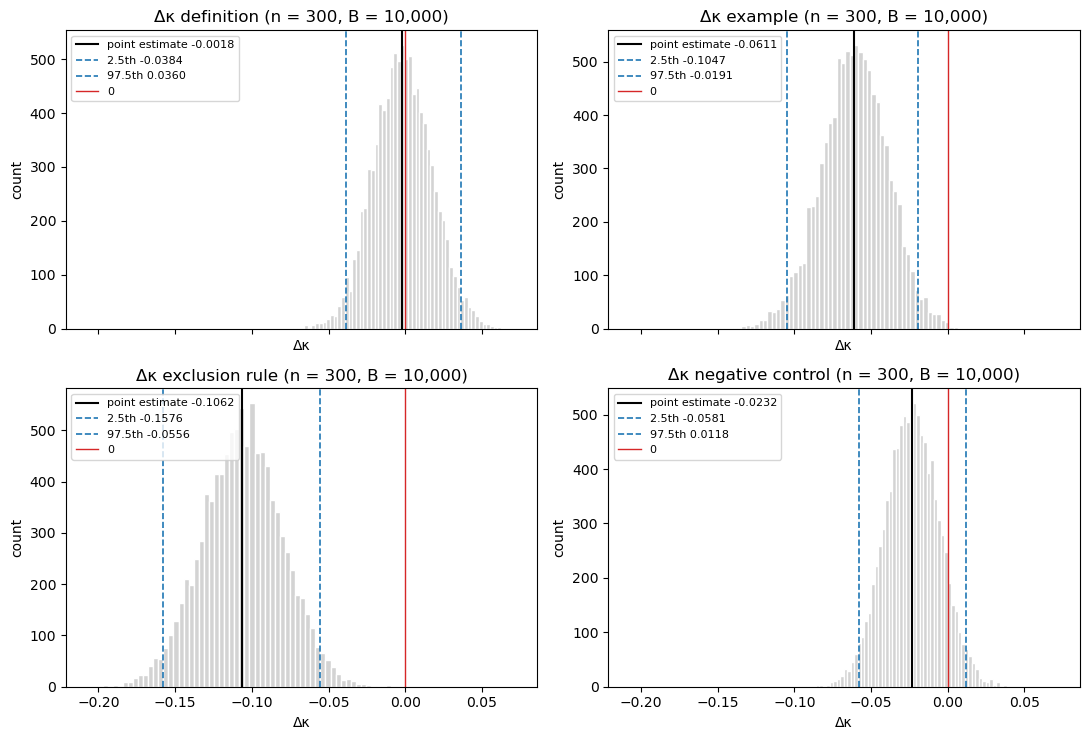

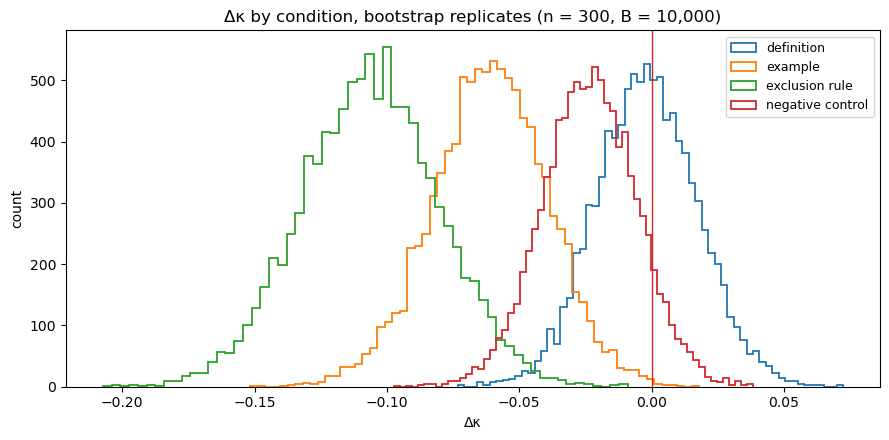

                 condition  corr(κ_base, κ_cond)  baseline κ width  condition κ width  Δκ width  Δκ width / baseline width
    definition_replacement                0.8870            0.1580             0.1572    0.0745                     0.4713
       example_replacement                0.8546            0.1580             0.1581    0.0857                     0.5421
exclusion_rule_replacement                0.7876            0.1580             0.1522    0.1020                     0.6456
          negative_control                0.9010            0.1580             0.1545    0.0700                     0.4428
                 condition  Δκ width / baseline width  sqrt(2(1-corr))
    definition_replacement                     0.4713           0.4755
       example_replacement                     0.5421           0.5393
exclusion_rule_replacement                     0.6456           0.6517
          negative_control                     0.4428           0.4449


In [13]:
# 5.2. Δκ by Condition — histograms, overlay, and correlation table

labels_short = {
    "definition_replacement": "definition",
    "example_replacement": "example",
    "exclusion_rule_replacement": "exclusion rule",
    "negative_control": "negative control",
}

# One histogram per condition
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, cond in zip(axes.ravel(), REPLACEMENTS):
    col = f"delta_kappa_{cond}"
    values = replicates[col].to_numpy()
    lo, hi = np.percentile(values, [2.5, 97.5], method="linear")
    ax.hist(values, bins=60, color="lightgray", edgecolor="white")
    ax.axvline(point[col], color="black", linewidth=1.5, label=f"point estimate {point[col]:.4f}")
    ax.axvline(lo, color="tab:blue", linestyle="--", linewidth=1.2, label=f"2.5th {lo:.4f}")
    ax.axvline(hi, color="tab:blue", linestyle="--", linewidth=1.2, label=f"97.5th {hi:.4f}")
    ax.axvline(0, color="tab:red", linewidth=1.0, label="0")
    ax.set_title(f"Δκ {labels_short[cond]} (n = 300, B = 10,000)")
    ax.set_xlabel("Δκ")
    ax.set_ylabel("count")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Four distributions in one figure
fig, ax = plt.subplots(figsize=(9, 4.5))
for cond in REPLACEMENTS:
    ax.hist(replicates[f"delta_kappa_{cond}"], bins=60, histtype="step", linewidth=1.3, label=labels_short[cond])
ax.axvline(0, color="tab:red", linewidth=1.0)
ax.set_title("Δκ by condition, bootstrap replicates (n = 300, B = 10,000)")
ax.set_xlabel("Δκ")
ax.set_ylabel("count")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Correlation between baseline κ and condition κ, and interval widths
base = replicates["kappa_baseline"].to_numpy()
base_lo, base_hi = np.percentile(base, [2.5, 97.5], method="linear")
rows = []
for cond in REPLACEMENTS:
    delta = replicates[f"delta_kappa_{cond}"].to_numpy()
    cond_k = base + delta                      # condition κ on the same replicate
    c_lo, c_hi = np.percentile(cond_k, [2.5, 97.5], method="linear")
    d_lo, d_hi = np.percentile(delta, [2.5, 97.5], method="linear")
    rows.append({
        "condition": cond,
        "corr(κ_base, κ_cond)": np.corrcoef(base, cond_k)[0, 1],
        "baseline κ width": base_hi - base_lo,
        "condition κ width": c_hi - c_lo,
        "Δκ width": d_hi - d_lo,
        "Δκ width / baseline width": (d_hi - d_lo) / (base_hi - base_lo),
    })
corr_table = pd.DataFrame(rows)
print(corr_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

corr_table["sqrt(2(1-corr))"] = np.sqrt(2 * (1 - corr_table["corr(κ_base, κ_cond)"]))
print(corr_table[["condition", "Δκ width / baseline width", "sqrt(2(1-corr))"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

### 5.3. Percentile Intervals

The 95% percentile interval uses the 2.5th and 97.5th percentiles of the bootstrap distribution, leaving 2.5% of the estimates in each tail.

`numpy.percentile(values, q, method="linear")` sorts the N values and interpolates between two neighbours.

For a proportion $p$ (0.025 or 0.975) the position in the sorted array (0-based) is

$$
\text{pos} = (N - 1) \times p
$$

With $N = 10{,}000$ and $p = 0.025$, $\text{pos} = 9999 \times 0.025 = 249.975$. Let $i = \lfloor \text{pos} \rfloor$ and $f = \text{pos} - i$. The percentile is the linear interpolation between the $i$-th and $(i+1)$-th sorted values:

$$
\text{percentile} = x_{(i)} + f \times \left(x_{(i+1)} - x_{(i)}\right)
$$

So the 2.5th percentile lies between the 249th and 250th sorted values (0-based), 97.5% of the way from the first to the second. For $p = 0.975$, $\text{pos} = 9749.025$, between the 9749th and 9750th sorted values.

The code reproduces this by hand for every column and checks the result against `numpy.percentile`. The comparison allows a tolerance of $10^{-12}$ because NumPy evaluates the interpolation in a slightly different floating-point order. 

Whether the central 95% of the bootstrap distribution works as a 95% confidence interval for the population value is a separate question. It concerns the justification of the bootstrap itself and is taken up in Section 6.

In [14]:
# 5.3. Percentile Intervals — hand interpolation checked against numpy.percentile

def manual_percentile(values, p):
    """Linear interpolation on the sorted values, the same rule as numpy.percentile(method='linear')."""
    s = np.sort(np.asarray(values, dtype=float))
    pos = (len(s) - 1) * p
    i = int(np.floor(pos))
    f = pos - i
    return s[i] + f * (s[i + 1] - s[i]), pos, i, f

rows = []
for col in ["kappa_baseline", *[f"delta_kappa_{c}" for c in REPLACEMENTS]]:
    values = replicates[col].to_numpy()
    for p in (0.025, 0.975):
        manual, pos, i, f = manual_percentile(values, p)
        numpy_value = np.percentile(values, p * 100, method="linear")
        assert np.isclose(manual, numpy_value, atol=1e-12), (col, p, manual, numpy_value)
        rows.append({"statistic": col, "p": p, "position": pos, "lower index": i, "fraction": f,
                     "manual": manual, "numpy": numpy_value})

print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                             statistic      p  position  lower index  fraction  manual   numpy
                        kappa_baseline 0.0250  249.9750          249    0.9750  0.5266  0.5266
                        kappa_baseline 0.9750 9749.0250         9749    0.0250  0.6846  0.6846
    delta_kappa_definition_replacement 0.0250  249.9750          249    0.9750 -0.0384 -0.0384
    delta_kappa_definition_replacement 0.9750 9749.0250         9749    0.0250  0.0360  0.0360
       delta_kappa_example_replacement 0.0250  249.9750          249    0.9750 -0.1047 -0.1047
       delta_kappa_example_replacement 0.9750 9749.0250         9749    0.0250 -0.0191 -0.0191
delta_kappa_exclusion_rule_replacement 0.0250  249.9750          249    0.9750 -0.1576 -0.1576
delta_kappa_exclusion_rule_replacement 0.9750 9749.0250         9749    0.0250 -0.0556 -0.0556
          delta_kappa_negative_control 0.0250  249.9750          249    0.9750 -0.0581 -0.0581
          delta_kappa_negative_control 0.9750 9749

## 6. Observations 🔬

### Center

The baseline κ bootstrap mean (0.6075) and median (0.6083) were close to the original point estimate (0.6085).

This shows that the bootstrap distribution is centered near the original estimate. However, it does not establish that the estimator is unbiased or that the estimate is close to the population value.

### Spread

The exclusion-rule Δκ distribution had a larger SD (0.0260) than the example-replacement distribution (0.0217).

Its 95% interval was also wider (0.1020 versus 0.0857), indicating lower precision.

### Shape

The baseline κ distribution was roughly bell-shaped, with a slightly longer left tail.

Its confidence interval extended slightly farther below the point estimate than above it.

### Interval Position

The 95% intervals for example and exclusion-rule replacement were entirely below zero.

The intervals for definition replacement and the negative control included zero. This does not establish that either replacement had no effect on agreement.

### Δκ Versus Baseline κ

The Δκ intervals were narrower than the baseline κ interval, ranging from 44% to 65% of its width.

Baseline κ and condition κ were strongly positively correlated across bootstrap replicates (r = 0.79 to 0.90).

Because the same utterances were resampled across conditions, the two κ estimates tended to move together. This reduced the variability of their difference, Δκ.

The observed CI width ratios were close to the values predicted by √(2(1 − r)), differing by less than 0.01. This formula is an approximation for CI width ratios under the assumption of equal spread.

Exclusion-rule replacement had the most changed labels (39 of 300) and the lowest correlation (r = 0.7876). This is a descriptive observation, not evidence that more label changes necessarily produce lower correlations.

### What This Experiment Does Not Answer

The bootstrap uses the original 300 utterances as a stand-in for the target population. By resampling these records, it approximates how the estimates would vary across different samples.

This approximation depends on how well the original sample represents the population. Rare categories with only one to four utterances provide limited information about category-specific variation.

The bootstrap does not separately estimate variability from rerunning the API or directly test the results on a new sample.

Experiment 04 examines how sample size affects sampling variability and confidence interval width.